In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Разширен инженерен и статистически анализ (60-литрова кутия MC16 eKW 1150/12500 Hybrid)

Този раздел представя три алтернативни индустриални статистически метода за анализ на стабилността на шприцмашината. За разлика от класическото търсене на единични аномалии (3-sigma), тези подходи оценяват дългосрочната пригодност и структурното поведение на производствения процес при големи детайли.



### 1. Изчисляване на Индексите за пригодност на процеса ($C_p$ и $C_{pk}$)
Това е ключов аналитичен метод в индустрията за оценка на способността на машината да произвежда детайли в рамките на зададените от инженерите допуски.

*   **$C_p$ (Potential Capability):** Изчислява максималния потенциал на машината, ако процесът е перфектно центриран. Формулата съпоставя общата ширина на толеранса с естественото разсейване на машината ($6\sigma$):
    $$C_p = \frac{USL - LSL}{6 \cdot \text{std}}$$
*   **$C_{pk}$ (Critical Capability):** Оценява реалното текущо състояние, като отчита дали средната стойност ($\mu$) се е изместила по-близо до някоя от двете граници на толеранса ($LSL$ или $USL$).
*   **Инженерно приложение за 60L кутия:** Чрез дефиниране на технологични граници около ключови параметри (например пиковото налягане или времето за дозиране), индексът показва количествено стабилността на машината по стандарта ($6\sigma$). Стойност на $C_{pk} > 1.33$ доказва изключително стабилно производство с пренебрежимо малък риск от брак.



### 2. Сравнителен анализ на вариацията чрез Вариационен коефициент ($CV$)
Когато се сравняват различни физически величини (например секунди, барове, милиметри и обороти), стандартното отклонение ($\text{std}$) не може да се използва директно като база за сравнение, тъй като зависи от мащаба на мерната единица.

За целта се изчислява Коефициентът на вариация ($CV$), който превръща разсейването в безразмерен процент спрямо средната стойност:
$$CV = \frac{\text{std}}{\text{mean}} \times 100\%$$

*   **Инженерен анализ за 60L кутия:** Този анализ дава директен отговор на въпроса: *„Коя подсистема на машината е най-нестабилна по време на работа?“* Сравняването на $CV (\%)$ между хидравличното налягане (`Pressure peak`), кинематиката на шнека (`Plasticising time`) и натоварването (`Maximum torque`) позволява на поддържащия екип да идентифицира износването на конкретни клапани, помпи или електрически задвижвания, преди те да са предизвикали реален брак.



### 3. Анализ на Времевите редове чрез Пълзящо средно (Moving Average)
Понеже записите във файла `mc16.csv` са последователни производствени цикли, те представляват времеви ред. Процесите на шприцоване често страдат от плавен "дрейф" – бавно и прогресивно изместване на параметрите поради постепенно нагряване на хидравличното масло, умора на метала или термично разширение на калъпа.

*   **Приложение на модела (Moving Average):** Изчисляването на пълзящо средно (например с прозорец от 5 цикъла) изглажда случайните моментни флуктуации и разкрива дългосрочния тренд на машината.
*   **Инженерно значение:** Прилагането на този метод върху параметъра `Cushion position (mm)`  показва дали обемът на пластмасата в края на впръскването има тенденция трайно да намалява или нараства в хода на производствената серия, което би довело до прогресивни промени в теглото и геометрията на кутиите.


### Пояснение на `Cushion position`
Тъй като в пряк превод това понятие звучи странно, ще добавя кратко пояснение. `Cushion position` или просто `Cushion - Възглавница`  означава остатъчна позиция на шнека след края на нагнетяването на стопилката в матрицата  (`packing / holding phase`). По-ясно казано, по време на впръскване шнека се движи напред и избутва/шприцова стопената пластмаса в матрицата. След като тя се напълни, се подава допълнително налягане  (holding pressure), за да се компенсира свиването на материала. Когато този етап приключи, шнекът не трябва да е стигнал до крайно предно положение и трябва да остане малко количество стопилка пред върха на шнека. Това разстояние е `Cushion position`.

1. ИНДЕКСИ ЗА ПРИГОДНОСТ НА ПРОЦЕСА (CAPABILITY STUDY):
Параметър: Pressure peak (bar)
Потенциален индекс Cp:  0.969
Реален индекс Cpk:      0.861 (Центриране на процеса)
Извод: Процесът не е достатъчно пригоден. Риск от дефекти извън толеранса.

2. КОЕФИЦИЕНТ НА ВАРИАЦИЯ (Кои физически параметри са най-нестабилни?):
                                   Вариация CV (%)
Injection start pressure (bar)               3.491
Cushion position (mm)                        2.957
Cushion minimum position (mm)                2.934
Plasticising start position (mm)             2.934
Maximum torque (Nm)                          0.966
Plasticising time (s)                        0.961
Switch-over pressure (bar)                   0.863
Pressure peak (bar)                          0.863
Mean torque (Nm)                             0.340
Plasticising start pressure (bar)            0.243
Pressure peak position (mm)                  0.204
Hold-on pressure (bar)                       0.157
Backpressure (bar)

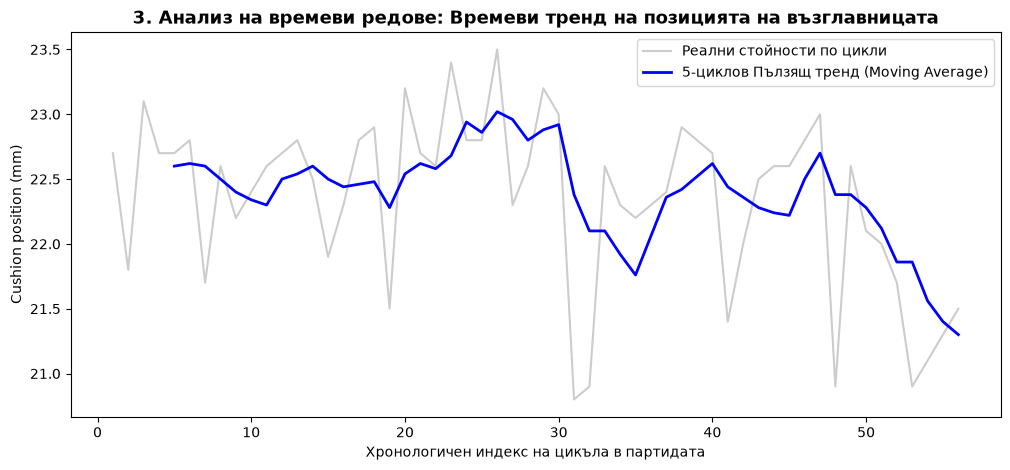

In [5]:
df = pd.read_csv('data/mc16.csv')
df_cycles = df[df['Cycle No.'] != 'Average'].dropna(subset=['Cycle No.']).copy()
for col in df_cycles.columns:
    if col != 'Cycle No.':
        df_cycles[col] = pd.to_numeric(df_cycles[col])


# 1: ИЗЧИСЛЯВАНЕ НА Cp И Cpk ЗА ПИКОВО НАЛЯГАНЕ

target_col = 'Pressure peak (bar)'
p_mean = df_cycles[target_col].mean()
p_std = df_cycles[target_col].std()

# Задаваме илюстративни инженерни граници: ±2.0 bar около средното ниво
LSL = 77.5
USL = 81.5

# Формули за Cp и Cpk
Cp = (USL - LSL) / (6 * p_std)
Cpu = (USL - p_mean) / (3 * p_std)
Cpl = (p_mean - LSL) / (3 * p_std)
Cpk = min(Cpu, Cpl)

print("1. ИНДЕКСИ ЗА ПРИГОДНОСТ НА ПРОЦЕСА (CAPABILITY STUDY):")
print(f"Параметър: {target_col}")
print(f"Потенциален индекс Cp:  {Cp:.3f}")
print(f"Реален индекс Cpk:      {Cpk:.3f} (Центриране на процеса)")
if Cpk < 1.0:
    print("Извод: Процесът не е достатъчно пригоден. Риск от дефекти извън толеранса.")
elif Cpk < 1.33:
    print("Извод: Процесът е умерено пригоден, но изисква наблюдение.")
else:
    print("Извод: Процесът е Six Sigma стабилен (изключително ниско ниво на брак).")


# 2: КОЕФИЦИЕНТ НА ВАРИАЦИЯ (CV%)

cv_results = {}
for col in df_cycles.columns:
    if col != 'Cycle No.':
        m = df_cycles[col].mean()
        s = df_cycles[col].std()
        if m > 0:
            cv_results[col] = (s / m) * 100

df_cv = pd.DataFrame.from_dict(cv_results, orient='index', columns=['Вариация CV (%)'])
df_cv = df_cv.sort_values('Вариация CV (%)', ascending=False)

print("\n2. КОЕФИЦИЕНТ НА ВАРИАЦИЯ (Кои физически параметри са най-нестабилни?):")
print(df_cv.round(3).to_string())


#3: ПЪЛЗЯЩО СРЕДНО (MOVING AVERAGE) ЗА ТРЕНД НА ВЪЗГЛАВНИЦАТА

df_sorted = df_cycles.sort_values('Cycle No.').reset_index(drop=True)
df_sorted['Cushion_MA_5'] = df_sorted['Cushion position (mm)'].rolling(window=5).mean()

plt.figure(figsize=(12, 5))
plt.plot(df_sorted.index, df_sorted['Cushion position (mm)'], alpha=0.4, label='Реални стойности по цикли', color='gray')
plt.plot(df_sorted.index, df_sorted['Cushion_MA_5'], label='5-циклов Пълзящ тренд (Moving Average)', color='blue', linewidth=2)
plt.title('3. Анализ на времеви редове: Времеви тренд на позицията на възглавницата', fontsize=13, fontweight='bold')
plt.xlabel('Хронологичен индекс на цикъла в партидата')
plt.ylabel('Cushion position (mm)')
plt.legend()
plt.show()
